In [12]:
from typing import TypedDict,List
from langgraph.graph import StateGraph 

In [13]:
class Agent(TypedDict):
    values: List[int]
    name: str
    result: int

In [14]:
def process_values(state: Agent) -> Agent:
    """This function handles multiple values and calculates their sum"""
    if "operation" in state and state["operation"] == "+":
        state["result"] = f"Hi {state['name']}, the sum of your values is {sum(state['values'])}"
    else:
        state["result"] = f"Hi {state['name']}, the product of your values is {eval('*'.join(map(str, state['values'])))}"
    
    return state

In [15]:
graph = StateGraph(Agent)
graph.add_node("processer",process_values)
graph.set_entry_point("processer")
graph.set_finish_point("processer")

app = graph.compile()

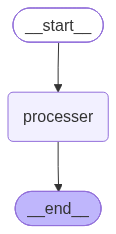

In [16]:
from IPython.display import display
display(app)

In [20]:
res = app.invoke({"name": "Alice", "values": [9, 2, 3], "operation": "*"},)
res

{'values': [9, 2, 3],
 'name': 'Alice',
 'result': 'Hi Alice, the product of your values is 54'}

In [18]:
print(res["result"])

Hi Alice, the product of your values is 6
